# Coding part for assignment 2 in Statistical Machine Learning

**Name**: Christian Ulrik Niekrenz \
**StudentID**: 21435375

In [73]:
# Imports
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
    (LinearDiscriminantAnalysis as LDA,
     QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

## 4.13

### (a)

In [74]:
# Load data
Weekly = load_data("Weekly")
Weekly.head()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,1990,0.816,1.572,-3.936,-0.229,-3.484,0.154976,-0.270,Down
1,1990,-0.270,0.816,1.572,-3.936,-0.229,0.148574,-2.576,Down
2,1990,-2.576,-0.270,0.816,1.572,-3.936,0.159837,3.514,Up
3,1990,3.514,-2.576,-0.270,0.816,1.572,0.161630,0.712,Up
4,1990,0.712,3.514,-2.576,-0.270,0.816,0.153728,1.178,Up


In [75]:
type(Weekly)

pandas.DataFrame

First we will have a look at the distribution of the return for the `lag1,...,5` given that the `direction` is either up or down, to figur out if there is any clear relationship here.

Based on these conditional histograms, there is no direct conclusion to wether or not the lag1,...,2 is correlated with the direction of todays movment.

Text(0.5, 0.98, 'Lag return distributions by current market direction')

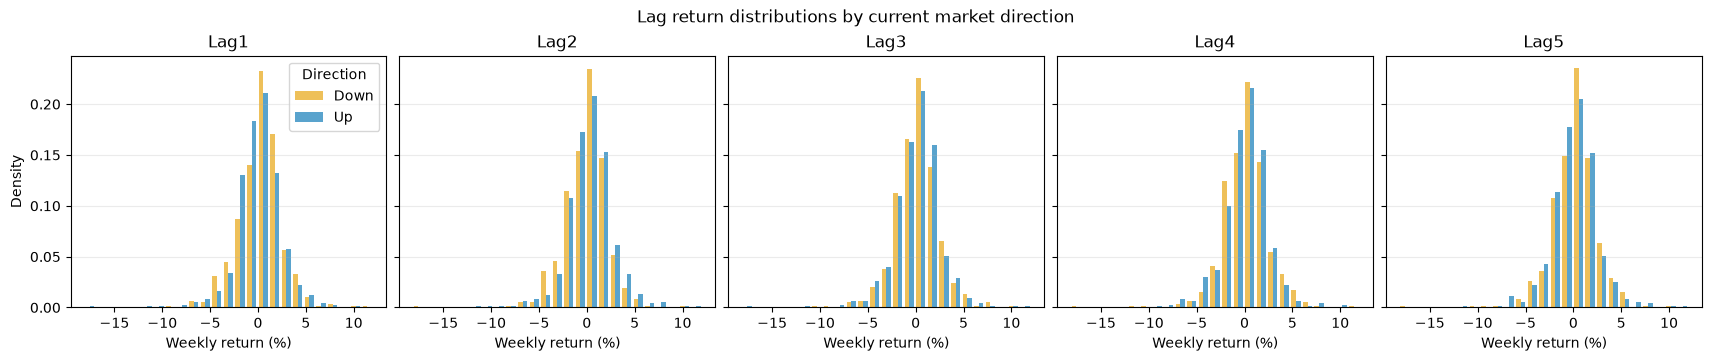

In [76]:
# Compare the distributions of each lag for weeks that went Up or Down
lags = [f"Lag{i}" for i in range(1, 6)]
directions = ["Down", "Up"]
colors = {"Down": "#E69F00", "Up": "#0072B2"}

fig, axes = subplots(1, 5, figsize=(17, 3.5), sharey=True, constrained_layout=True)
for ax, lag in zip(axes, lags):
    lag_by_direction = [
        Weekly.loc[Weekly["Direction"] == direction, lag]
        for direction in directions
    ]
    ax.hist(
        lag_by_direction,
        bins=25,
        density=True,
        alpha=0.65,
        color=[colors[direction] for direction in directions],
        label=directions,
    )
    ax.set_title(lag)
    ax.set_xlabel("Weekly return (%)")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Density")
axes[0].legend(title="Direction")
fig.suptitle("Lag return distributions by current market direction")

Lets have a look at the correlation between the different features, the surragot target in direction and the actual return of today. This can be seen in the matrix below, this also tells the same story no direct correlation between the features and the target.

,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction (Up=1)
Lag1,1.00,-0.07,0.06,-0.07,-0.01,-0.06,-0.08,-0.05
Lag2,-0.07,1.00,-0.08,0.06,-0.07,-0.09,0.06,0.07
Lag3,0.06,-0.08,1.00,-0.08,0.06,-0.07,-0.07,-0.02
Lag4,-0.07,0.06,-0.08,1.00,-0.08,-0.06,-0.01,-0.02
Lag5,-0.01,-0.07,0.06,-0.08,1.00,-0.06,0.01,-0.02
Volume,-0.06,-0.09,-0.07,-0.06,-0.06,1.00,-0.03,-0.02
Today,-0.08,0.06,-0.07,-0.01,0.01,-0.03,1.00,0.72
Direction (Up=1),-0.05,0.07,-0.02,-0.02,-0.02,-0.02,0.72,1.00


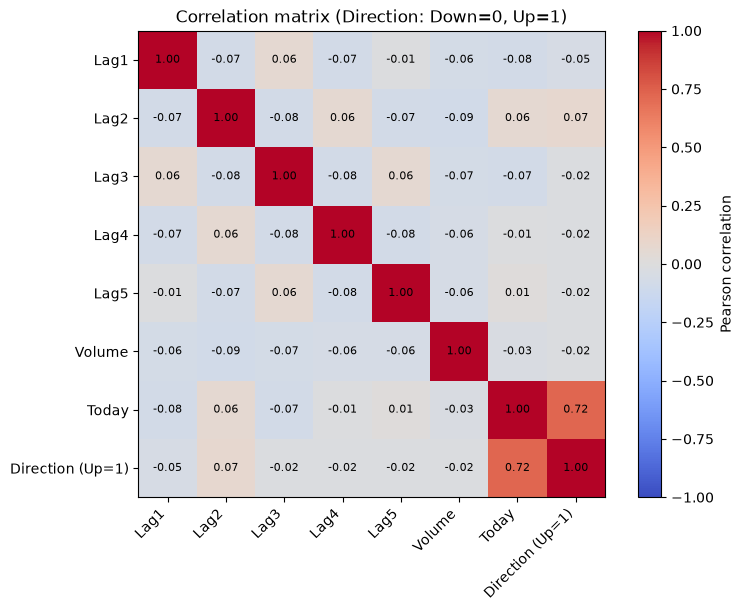

In [77]:
# Correlation matrix for lag returns, volume, today's return, and direction
lags = [f"Lag{i}" for i in range(1, 6)]

correlation_data = Weekly[lags + ["Volume", "Today"]].copy()
correlation_data["Direction (Up=1)"] = Weekly["Direction"].map(
    {"Down": 0, "Up": 1}
)

correlation_matrix = correlation_data.corr()

fig, ax = subplots(figsize=(8, 6), constrained_layout=True)
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_yticklabels(correlation_matrix.index)

for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        ax.text(
            column,
            row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=8,
        )

ax.set_title("Correlation matrix (Direction: Down=0, Up=1)")
fig.colorbar(image, ax=ax, label="Pearson correlation")

correlation_matrix.round(2)

### (b)

Lets fit the logistic-regression using the statmodels library,

In [78]:
predictors = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]

X = MS(predictors).fit_transform(Weekly)
y = Weekly["Direction"] == "Up"

weekly_glm = sm.GLM(y, X, family=sm.families.Binomial())
weekly_results = weekly_glm.fit()

summarize(weekly_results)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


Yes, in this full model, it looks like `lag2` is statistical signifigant with a p-value of $0.03$, at least with a threshold of $\alpha=0.05$.

### (c)

Based in (b) we will now create a confusion matrix on the training data.

In [79]:
predicted = np.where(weekly_results.predict(X) >= 0.5, "Up", "Down")
cm = confusion_table(predicted, Weekly["Direction"])
cm

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


We see that the model predict right in $56.1%$ of cases.

In [80]:
(predicted == Weekly["Direction"].to_numpy()).mean()

np.float64(0.5610651974288338)

When we have classification task, we can compare the predicted classes with the actually classes, which is exactly what the confusion-matrix does. In relation to this, we can calculate the proportion where it predicts right for the positiv class (up) and where it does not, and the same for the negativ class.

In [81]:
TN = cm.loc["Down", "Down"]
FN = cm.loc["Down", "Up"]
FP = cm.loc["Up", "Down"]
TP = cm.loc["Up", "Up"]

FPR = FP / (FP + TN)
TPR = TP / (TP + FN)
FNR = FN / (FN + TP)
TNR = TN / (TN + FP)

print(f"FPR: {FPR:.3f}")
print(f"TPR: {TPR:.3f}")
print(f"FNR: {FNR:.3f}")
print(f"TNR: {TNR:.3f}")

FPR: 0.888
TPR: 0.921
FNR: 0.079
TNR: 0.112


Here we see the the TPR is high, meaning that it predicts the `up` correct most of the time, but also that the FPR is high. This is because the model mostly just predicts `up` for all rows.

### (d)

In [82]:
train = Weekly[Weekly["Year"] <= 2008]
test = Weekly[Weekly["Year"] >= 2009]

X_train = MS(["Lag2"]).fit_transform(train)
X_test = MS(["Lag2"]).fit_transform(test)
y_train = train["Direction"] == "Up"

lag2_model = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Binomial()
).fit()

predicted = np.where(lag2_model.predict(X_test) >= 0.5, "Up", "Down")

confusion_table(predicted, test["Direction"])

Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Above we have the confusion matrix, with the same problem as the previous model. The overall correct prediction is $62.5%$, which is better than before and also on unseen data.

In [83]:
(predicted == test["Direction"].to_numpy()).mean()

np.float64(0.625)

### (e), (f), (g), (h)

Using the same data as from (d), and running all the four models in a loop,

In [84]:
X_train_lag2 = train[["Lag2"]]
X_test_lag2 = test[["Lag2"]]
y_train = train["Direction"]

classifiers = {
    "LDA": LDA(),
    "QDA": QDA(),
    "KNN (K=1)": KNeighborsClassifier(n_neighbors=1),
    "Naive Bayes": GaussianNB(),
}

predictions = {}

for name, classifier in classifiers.items():
    classifier.fit(X_train_lag2, y_train)
    predictions[name] = classifier.predict(X_test_lag2)

    print(f"\n{name} confusion matrix (rows: predicted; columns: actual)")
    print(confusion_table(predictions[name], test["Direction"]))


LDA confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56

QDA confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61

KNN (K=1) confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down         22  31
Up           21  30

Naive Bayes confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61


In [85]:
accuracy_table = pd.DataFrame({
    "Model": list(predictions.keys()),
    "Correct Predictions": [
        (predictions[name] == test["Direction"].to_numpy()).sum()
        for name in predictions
    ],
    "Accuracy": [
        (predictions[name] == test["Direction"].to_numpy()).mean()
        for name in predictions
    ],
})

accuracy_table["Accuracy"] = accuracy_table["Accuracy"].map("{:.1%}".format)
accuracy_table

,Model,Correct Predictions,Accuracy
0,LDA,65,62.5%
1,QDA,61,58.7%
2,KNN (K=1),52,50.0%
3,Naive Bayes,61,58.7%


### (i)

LDA and logistic regreesion both give the same accuary on the training data, and the highest of tall the models.

### (j)

I am AI come up with 20 different feature combinations, and tried all of them on the different models. Also since KKN is the only one with a hyperparameter, we also tried different for all the feature combinations.

In [86]:
def make_features(data, names):
    values = {
        **{
            col: data[col]
            for col in [f"Lag{i}" for i in range(1, 6)] + ["Volume"]
        },
        "Lag1^2": data["Lag1"] ** 2,
        "Lag2^2": data["Lag2"] ** 2,
        "Lag3^2": data["Lag3"] ** 2,
        "Lag4^2": data["Lag4"] ** 2,
        "Lag5^2": data["Lag5"] ** 2,
        "Lag2^3": data["Lag2"] ** 3,
        "|Lag2|": data["Lag2"].abs(),
        "Lag1*Lag2": data["Lag1"] * data["Lag2"],
        "Lag2*Lag3": data["Lag2"] * data["Lag3"],
        "Lag3*Lag4": data["Lag3"] * data["Lag4"],
        "Lag4*Lag5": data["Lag4"] * data["Lag5"],
        "Lag2*Volume": data["Lag2"] * data["Volume"],
        "Volume^2": data["Volume"] ** 2,
    }
    return pd.DataFrame(
        {name: values[name] for name in names},
        index=data.index,
    )


feature_sets = {
    "01 Lag2": ["Lag2"],
    "02 Lag1 + Lag2": ["Lag1", "Lag2"],
    "03 Lag2 + Lag3": ["Lag2", "Lag3"],
    "04 Lag1-Lag3": ["Lag1", "Lag2", "Lag3"],
    "05 All five lags": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"],
    "06 All lags + Volume": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"],
    "07 Lag2 + Volume": ["Lag2", "Volume"],
    "08 Lag1 + Lag2 + Volume": ["Lag1", "Lag2", "Volume"],
    "09 Lag2 + Lag4": ["Lag2", "Lag4"],
    "10 Odd lags": ["Lag1", "Lag3", "Lag5"],
    "11 Lag2 + square": ["Lag2", "Lag2^2"],
    "12 Lag2 + cube": ["Lag2", "Lag2^3"],
    "13 Lag2 + absolute value": ["Lag2", "|Lag2|"],
    "14 Lag1 + Lag2 + interaction": ["Lag1", "Lag2", "Lag1*Lag2"],
    "15 Lag1 + Lag2 + squares": ["Lag1", "Lag2", "Lag1^2", "Lag2^2"],
    "16 Lags 1-3 + interaction": ["Lag1", "Lag2", "Lag3", "Lag1*Lag2"],
    "17 Lag2 + Volume + interaction": ["Lag2", "Volume", "Lag2*Volume"],
    "18 Lag2 + Volume + squares": ["Lag2", "Volume", "Lag2^2", "Volume^2"],
    "19 All lags + squares": [
        "Lag1", "Lag2", "Lag3", "Lag4", "Lag5",
        "Lag1^2", "Lag2^2", "Lag3^2", "Lag4^2", "Lag5^2",
    ],
    "20 All lags + interactions": [
        "Lag1", "Lag2", "Lag3", "Lag4", "Lag5",
        "Lag1*Lag2", "Lag2*Lag3", "Lag3*Lag4", "Lag4*Lag5",
    ],
}

non_knn_models = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "LDA": LDA(),
    "QDA": QDA(),
    "Naive Bayes": GaussianNB(),
}

records = []
actual = test["Direction"].to_numpy()

for feature_set, feature_names in feature_sets.items():
    X_train_features = make_features(train, feature_names)
    X_test_features = make_features(test, feature_names)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_features)
    X_test_scaled = scaler.transform(X_test_features)

    for method, model in non_knn_models.items():
        model.fit(X_train_scaled, train["Direction"])
        predicted = model.predict(X_test_scaled)

        records.append({
            "Method": method,
            "Predictors": feature_set,
            "K": "-",
            "Accuracy": (predicted == actual).mean(),
            "Predicted": predicted,
        })

    for k in [1, 3, 5, 10, 20, 50]:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train_scaled, train["Direction"])
        predicted = model.predict(X_test_scaled)

        records.append({
            "Method": "KNN",
            "Predictors": feature_set,
            "K": k,
            "Accuracy": (predicted == actual).mean(),
            "Predicted": predicted,
        })

leaderboard = pd.DataFrame([
    {
        "Method": result["Method"],
        "Predictors": result["Predictors"],
        "K": result["K"],
        "Accuracy": result["Accuracy"],
    }
    for result in records
]).sort_values("Accuracy", ascending=False)

display(leaderboard.head(10).style.format({"Accuracy": "{:.1%}"}))

best = max(records, key=lambda result: result["Accuracy"])
print(
    f"Best: {best['Method']} | {best['Predictors']} | "
    f"K={best['K']} | Accuracy={best['Accuracy']:.1%}"
)
print("Confusion matrix (rows: predicted; columns: actual):")
print(confusion_table(best["Predicted"], test["Direction"]))

,Method,Predictors,K,Accuracy
142,QDA,15 Lag1 + Lag2 + squares,-,64.4%
0,Logistic regression,01 Lag2,-,62.5%
21,LDA,03 Lag2 + Lag3,-,62.5%
1,LDA,01 Lag2,-,62.5%
80,Logistic regression,09 Lag2 + Lag4,-,62.5%
102,QDA,11 Lag2 + square,-,62.5%
81,LDA,09 Lag2 + Lag4,-,62.5%
20,Logistic regression,03 Lag2 + Lag3,-,62.5%
110,Logistic regression,12 Lag2 + cube,-,62.5%
100,Logistic regression,11 Lag2 + square,-,62.5%


Best: QDA | 15 Lag1 + Lag2 + squares | K=- | Accuracy=64.4%
Confusion matrix (rows: predicted; columns: actual):
Truth      Down  Up
Predicted          
Down         20  14
Up           23  47


In this case the only model metter that the logistic regression and LDA is a QDR with feature "Lag1 + Lag2 + squares", where you square both features.

## 4.14

### (a)

In [87]:
Auto = load_data("Auto")
Auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
name,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
ford torino,17.0,8,302.0,140,3449,10.5,70,1


Lets create the surragot 0-1 variable `mpg01`

In [88]:
Auto["mpg01"] = (Auto["mpg"] >= Auto["mpg"].median()).astype(int)
Auto["mpg"].median()

np.float64(22.75)

In [89]:
Auto[["mpg","mpg01"]].head()

,mpg,mpg01
name,,
chevrolet chevelle malibu,18.0,0
buick skylark 320,15.0,0
plymouth satellite,18.0,0
amc rebel sst,16.0,0
ford torino,17.0,0


### (b)

Lets make stratisfied boxplots for each of the features, based on the value of `mpg01`

Text(0.5, 0.98, 'Auto features grouped by MPG category')

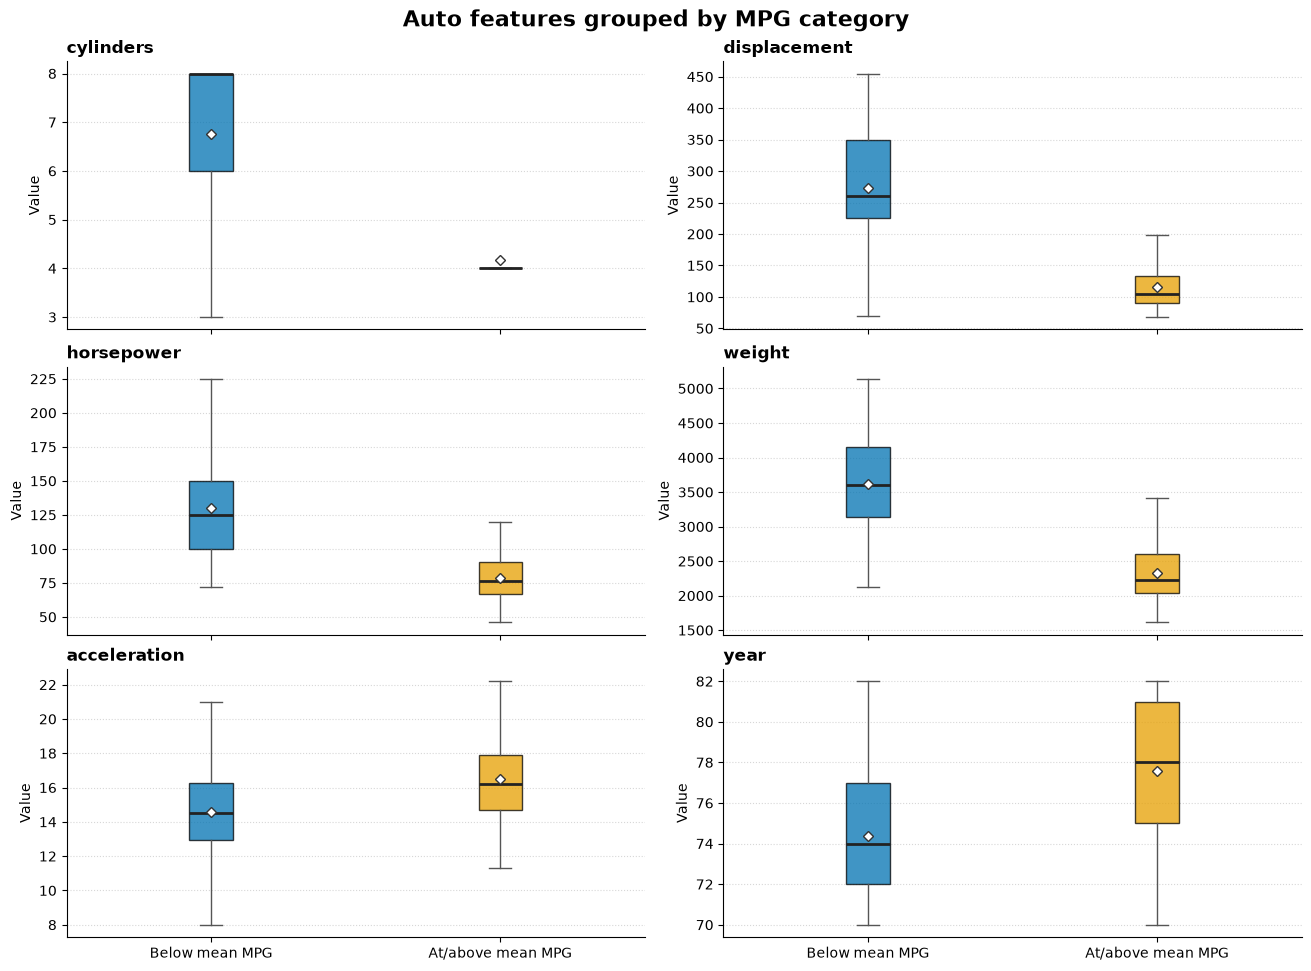

In [90]:
features = [
    column
    for column in Auto.select_dtypes(include=np.number).columns
    if column not in ["mpg", "mpg01", "origin"]
]

ncols = 2
nrows = (len(features) + ncols - 1) // ncols

fig, axes = subplots(
    nrows,
    ncols,
    figsize=(13, 3.2 * nrows),
    sharex=True,
    constrained_layout=True,
)
axes = np.asarray(axes).ravel()

group_colors = ["#0072B2", "#E69F00"]

for ax, feature in zip(axes, features):
    groups = [
        Auto.loc[Auto["mpg01"] == group, feature].dropna()
        for group in [0, 1]
    ]

    boxplot = ax.boxplot(
        groups,
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "#333333",
            "markersize": 5,
        },
        medianprops={"color": "#222222", "linewidth": 2},
        whiskerprops={"color": "#555555"},
        capprops={"color": "#555555"},
    )

    for patch, color in zip(boxplot["boxes"], group_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_title(feature, loc="left", fontweight="bold")
    ax.set_ylabel("Value")
    ax.set_xticks([1, 2], ["Below mean MPG", "At/above mean MPG"])
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in axes[len(features):]:
    ax.set_visible(False)

fig.suptitle(
    "Auto features grouped by MPG category",
    fontsize=16,
    fontweight="bold",
)

I would say `cylinders`, `displacement`, `weight` and `horsepower` all look like strong predictores, since the marginal conditional distributions looks different.

### (c)

In [91]:
train, test = train_test_split(Auto, test_size=0.2, random_state=0)

### (d)

We perform LDA, this results in a test error of $0.139$

In [92]:
predictors = ["cylinders", "displacement", "horsepower", "weight"]

X_train, y_train = train[predictors], train["mpg01"]
X_test, y_test = test[predictors], test["mpg01"]

lda = LDA().fit(X_train, y_train)
pred = lda.predict(X_test)

print(confusion_table(pred, y_test))
test_error = (pred != y_test).mean()
print(f"Test error: {test_error:.3f}")

Truth       0   1
Predicted        
0          34   3
1           8  34
Test error: 0.139


### (e), (f), (g), (h)

Since all the models will use the same data, and evaluated the same, we do it all in one big loop.

In [93]:
models = {
    "LDA (d)": LDA(),
    "QDA (e)": QDA(),
    "Logistic (f)": LogisticRegression(max_iter=1000),
    "Naive Bayes (g)": GaussianNB(),
}
for k in [1, 3, 5, 7, 9, 11, 15, 21, 31]:
    models[f"KNN K={k} (h)"] = KNeighborsClassifier(n_neighbors=k)

errors = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    errors[name] = (model.predict(X_test) != y_test).mean()
    print(f"{name:<18} test error = {errors[name]:.3f}")

knn_errors = {name: err for name, err in errors.items() if name.startswith("KNN")}
best_knn = min(knn_errors, key=knn_errors.get)
print(f"\nBest KNN: {best_knn} (test error {knn_errors[best_knn]:.3f})")

LDA (d)            test error = 0.139
QDA (e)            test error = 0.139
Logistic (f)       test error = 0.127
Naive Bayes (g)    test error = 0.127
KNN K=1 (h)        test error = 0.114
KNN K=3 (h)        test error = 0.101
KNN K=5 (h)        test error = 0.152
KNN K=7 (h)        test error = 0.152
KNN K=9 (h)        test error = 0.165
KNN K=11 (h)       test error = 0.165
KNN K=15 (h)       test error = 0.177
KNN K=21 (h)       test error = 0.177
KNN K=31 (h)       test error = 0.177

Best KNN: KNN K=3 (h) (test error 0.101)


The best everall model, in terms of test error, is the KNN with k=3.

## 5.5

### (a)

Frist lets train the model on all the data:

In [94]:
np.random.seed(0)

Default = load_data("Default")
Default["student"] = (Default["student"] == "Yes").astype(int)
y = (Default["default"] == "Yes").astype(int)

full_fit = sm.GLM(y, MS(["income", "balance"]).fit_transform(Default), family=sm.families.Binomial()).fit()
full_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Fri, 23 Oct 2026   Deviance:                       1579.0
Time:                        16:01:21   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    -11.5405      0.435    -26.544      0.000     -12.393     -10.688
income      2.081e-05   4.99e-06      4.174      0.000     1.1e-05    3.06e-05
balance        0.0056      0.000     24.835      0.000       0.005       0.006
==============================================================================
"""

### (b)

Now lets create a function, that takes in a seed used for the random selection of the train and test sets. This function will be reused in the downstream questions.

In [95]:
def val_error(cols, seed):
    train, valid = train_test_split(Default, test_size=0.5, random_state=seed)
    fit = sm.GLM(y[train.index], MS(cols).fit_transform(train), family=sm.families.Binomial()).fit()
    prob = fit.predict(MS(cols).fit_transform(valid))
    return ((prob > 0.5).astype(int) != y[valid.index]).mean()

In [96]:
val_error(["income", "balance"], 0)

np.float64(0.029)

### (c)

We now run the function with three different seeds.

In [97]:
for seed in [1, 2, 3]:
    print(seed, val_error(["income", "balance"], seed))

1 0.025
2 0.0248
3 0.0248


### (d)

Lets now include the `student` variable, and train the model with tree different splits.

In [98]:
for seed in [1, 2, 3]:
    print(seed, val_error(["income", "balance", "student"], seed))

1 0.0262
2 0.0254
3 0.0252


In general i looks like the inclussion of the `student` variable does not help, since the test error increases on average.

## 5.6